# Feature selection: LSTM

**Mục tiêu:** loại các feature không cần thiết (không mang thông tin, trùng lặp, hoặc không giúp dự báo). Lợi ích: mô hình nhỏ hơn, ít nhiễu, ít overfit và controller online cần thu ít metric hơn.

Quy trình **giống hệt** cho LSTM và GAT-GRU (code trong `modeling-common/feature_selection.py` và `forecast_torch.py`), chỉ dùng **train + val**. Tập test không được nhìn tới.

| Bước | Phương pháp | Dữ liệu |
|---|---|---|
| 1. Lọc thống kê | (a) gần hằng số: std ≈ 0 hoặc một giá trị chiếm > 99%; (b) độ liên quan = \|Spearman ρ\| giữa feature tại t và target tại t+1..t+6; (c) trùng lặp: \|ρ\| > 0,95 với feature đã giữ thì bỏ feature kém liên quan hơn | train |
| 2. Permutation importance | Huấn luyện LSTM với cấu hình mặc định trên tập đã lọc. Xáo trộn từng feature (và từng nhóm) trên val, đo MAE tăng bao nhiêu. Giữ feature khi Δ > 1 độ lệch chuẩn qua các lần lặp | train → val |
| 3. Kiểm tra lại | Huấn luyện lại với tập đã chọn. Nếu val MAE xấu hơn tập đã lọc quá 2%, quay về tập đã lọc | train → val |

Feature bắt buộc: `rps_in`, `cpu_cores`, `replicas`.

**Dữ liệu:** các run trong `dataset/raw/` (kịch bản nhpp, mmpp, pareto, onoff, thu khi HPA bật). Split dùng chung `dataset/splits.json`, đầu ra `dataset/processed/lstm/` hoặc `artifacts/comparison/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'modeling-common').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'modeling-common').exists():
    raise FileNotFoundError('Cannot locate repository root')
COMMON = ROOT / 'modeling-common'   # code dùng chung cho GAT-GRU và LSTM
sys.path.insert(0, str(COMMON))
import forecast_data as fd

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

import feature_selection as fs

In [2]:
TAG = '_math'                     # dataset math-load-testing, giống notebook tiền xử lý
PROCESSED = ROOT / 'dataset' / 'processed' / 'lstm'
DEMO = PROCESSED.name.endswith('_demo')
MODEL = 'lstm'
runs, meta = fd.load_runs_npz(PROCESSED / 'runs_raw.npz')
splits = meta['splits']
if 'data_contract' not in meta:
    raise ValueError('runs_raw.npz is missing data_contract; rerun preprocess_lstm.ipynb')
edges = [tuple(e) for e in meta['edges']]
CORR_THRESHOLD = 0.95
DOMINANCE = 0.99
RETRAIN_TOLERANCE = 0.02     # bước 3: chấp nhận tập đã chọn nếu val MAE không xấu hơn quá 2%
print('PROCESSED =', PROCESSED.resolve(), '| runs =', len(runs), '| edges =', len(edges))

PROCESSED = F:\0. UIT\KLTN\thesis-gnn-rl-autoscaling\lstm-load-testing\processed_math | runs = 32 | edges = 0


## Bước 1. Lọc thống kê (train)

In [3]:
train = fd.train_arrays(runs, splits)
kept_node, report_node, corr_node = fs.filter_node_features(train, fd.HORIZON, forced=fd.FORCED_FEATURES,
                                                            dominance=DOMINANCE, corr_threshold=CORR_THRESHOLD)
print('Giữ sau bước 1:', kept_node)
report_node.round(4)

Giữ sau bước 1: ['rps_in', 'rps_in_delta', 'rps_per_replica', 'latency_p50_ms', 'latency_p95_ms', 'cpu_cores', 'cpu_util_request', 'cpu_throttle_ratio', 'cpu_sidecar_cores', 'mem_mib', 'net_rx_kBps', 'net_tx_kBps', 'replicas']


,group,std,dominant_value_frac,relevance_|rho|,status
rps_in,load,7.6316,0.2241,0.3549,kept: forced
cpu_cores,resource,0.1551,0.0002,0.3508,kept: forced
net_rx_kBps,resource,43.8763,0.0001,0.3482,kept
net_tx_kBps,resource,172.8334,0.0001,0.3459,kept
cpu_util_request,resource,0.2083,0.0002,0.3304,kept
cpu_sidecar_cores,resource,0.2119,0.0002,0.3303,kept
rps_per_replica,load,3.0154,0.2241,0.3288,kept
latency_p50_ms,perf,48.9801,0.2241,0.3182,kept
latency_p95_ms,perf,154.7490,0.2241,0.3094,kept
mem_mib,resource,73.5297,0.0078,0.1661,kept


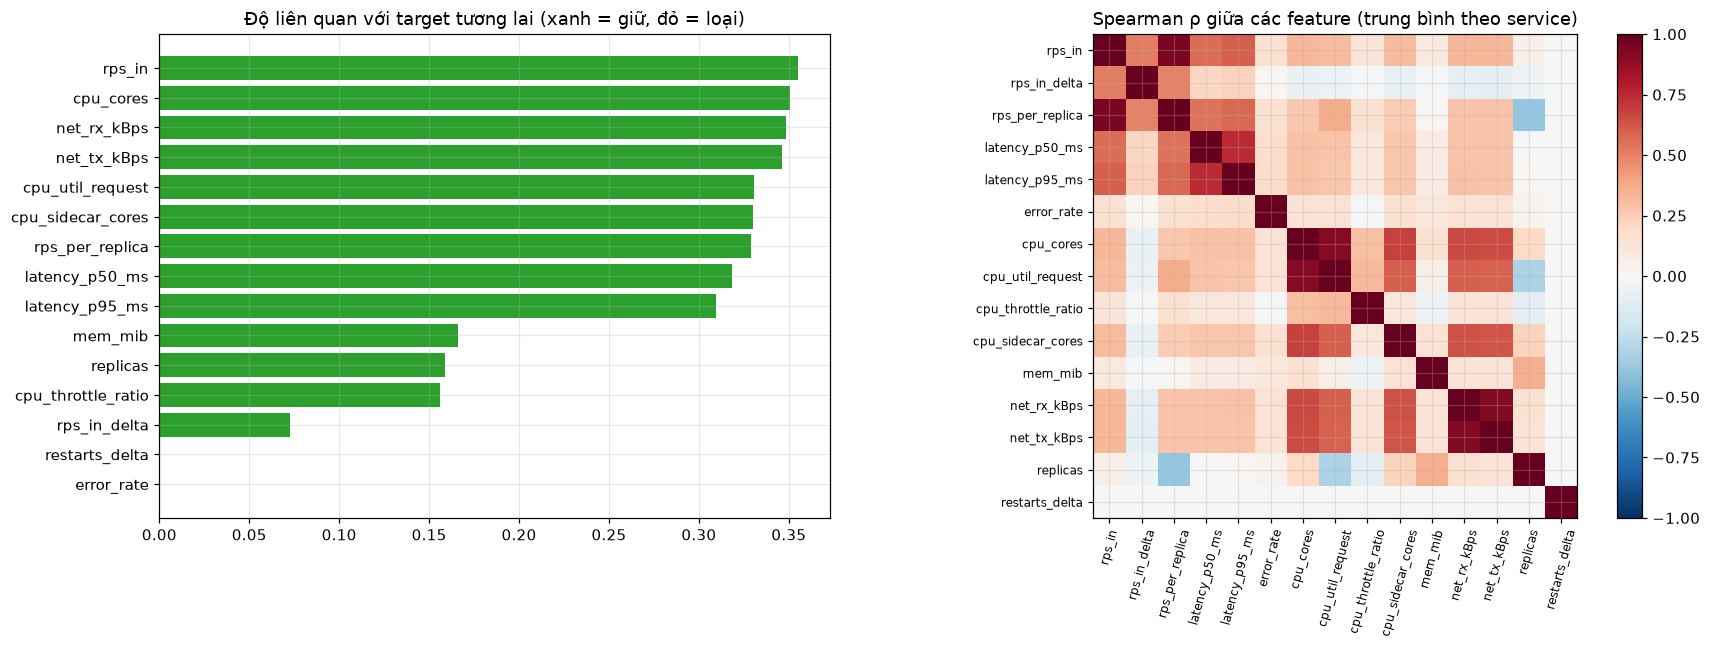

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.2]})
r = report_node.sort_values('relevance_|rho|')
colors = ['C2' if s.startswith('kept') else 'C3' for s in r.status]
axes[0].barh(r.index, r['relevance_|rho|'], color=colors)
axes[0].set_title('Độ liên quan với target tương lai (xanh = giữ, đỏ = loại)')
im = axes[1].imshow(corr_node, cmap='RdBu_r', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr_node)), corr_node.columns, rotation=75, fontsize=8)
axes[1].set_yticks(range(len(corr_node)), corr_node.index, fontsize=8)
axes[1].set_title('Spearman ρ giữa các feature (trung bình theo service)')
fig.colorbar(im, ax=axes[1])
fig.tight_layout()
plt.show()

In [5]:
kept_edge = []   # LSTM không có cạnh

## Bước 2. Permutation importance với LSTM
Cần PyTorch (`pip install -r ../modeling-common/requirements-ml.txt`). Mô hình được huấn luyện với `DEFAULT_CONFIG` (không tune), vì mục đích chỉ là xếp hạng feature. Tune được làm sau, trên tập đã chọn.

In [6]:
import forecast_torch as ft
B = ft.DEMO_BUDGET if DEMO else ft.BUDGET
cfg = dict(ft.DEFAULT_CONFIG[MODEL])
if DEMO:
    cfg['max_epochs'] = ft.DEMO_BUDGET['max_epochs']
data = ft.Data(runs, splits, kept_node, kept_edge, contract=meta['data_contract'])
model, val_filtered, hist, use_edges = ft.fit_one(MODEL, cfg, data, edges, seed=0)
print(f'val MAE (scaled) với tập đã lọc: {val_filtered:.4f} | epochs: {len(hist)} | params: {ft.n_params(model):,}')

groups = {}
for f in kept_node:
    groups.setdefault('group:' + fd.NODE_FEATURES[f][0], []).append(f)
if use_edges:
    groups['group:edge'] = list(kept_edge)
importance, base = ft.permutation_importance(model, data.get(cfg['window'], 'val'), data.node_feats,
                                             data.edge_feats, use_edges, groups, n_repeats=B['importance_repeats'])
importance.sort_values('delta_mean', ascending=False).round(5)

val MAE (scaled) với tập đã lọc: 0.1196 | epochs: 60 | params: 55,352


,type,delta_mean,delta_std
feature,,,
group:load,group,0.11326,0.00286
group:resource,group,0.05475,0.00182
rps_in,node,0.03358,0.00175
rps_per_replica,node,0.03272,0.00074
rps_in_delta,node,0.02184,0.00028
cpu_cores,node,0.01482,0.00042
group:capacity,group,0.01192,0.00035
replicas,node,0.01190,0.00046
cpu_sidecar_cores,node,0.01126,0.00033


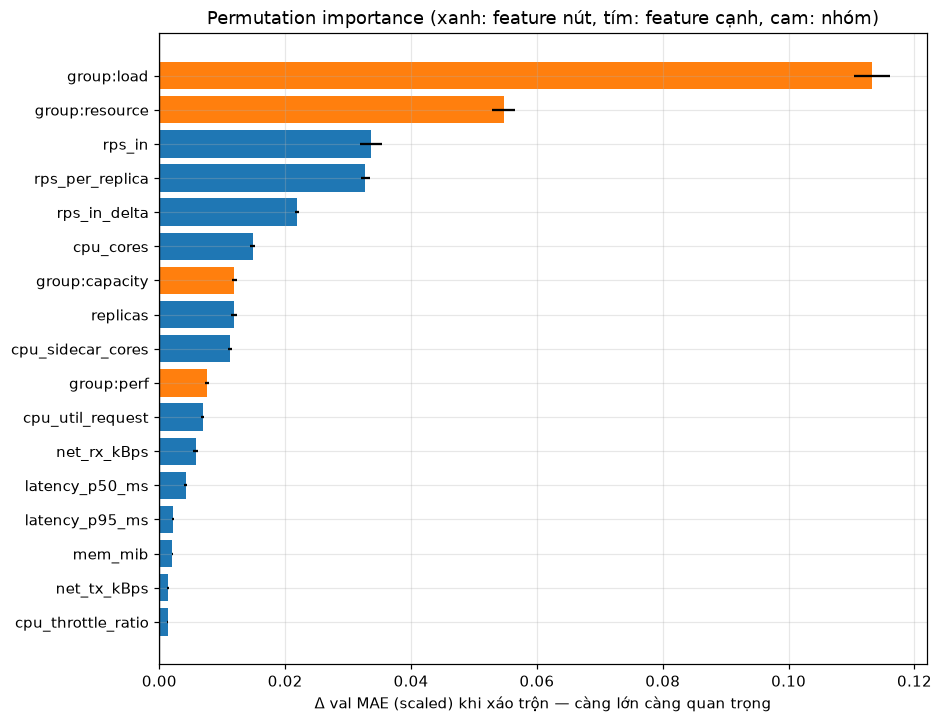

In [7]:
imp = importance.sort_values('delta_mean')
fig, ax = plt.subplots(figsize=(9, 0.35 * len(imp) + 1.5))
ax.barh(imp.index, imp.delta_mean, xerr=imp.delta_std,
        color=['C1' if t == 'group' else 'C4' if t == 'edge' else 'C0' for t in imp.type])
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Δ val MAE (scaled) khi xáo trộn — càng lớn càng quan trọng')
ax.set_title('Permutation importance (xanh: feature nút, tím: feature cạnh, cam: nhóm)')
plt.show()

## Bước 3. Chọn và kiểm tra lại

In [8]:
sel_node, status_node = fs.select_by_importance(importance[importance.type == 'node'], fd.FORCED_FEATURES)
sel_edge, status_edge = (fs.select_by_importance(importance[importance.type == 'edge'], [])
                         if use_edges else (list(kept_edge), {}))
data_sel = ft.Data(runs, splits, sel_node, sel_edge, contract=meta['data_contract'])
_, val_selected, _, _ = ft.fit_one(MODEL, cfg, data_sel, edges, seed=0)
accepted = val_selected <= val_filtered * (1 + RETRAIN_TOLERANCE)
final_node, final_edge = (sel_node, sel_edge) if accepted else (kept_node, list(kept_edge))
print(f'val MAE: tập đã lọc {val_filtered:.4f} | tập đã chọn {val_selected:.4f} -> '
      f'{"dùng tập đã chọn" if accepted else "giữ tập đã lọc (tập chọn làm xấu val)"}')
print('Feature nút cuối cùng :', final_node)
print('Feature cạnh cuối cùng:', final_edge)
pd.DataFrame({'bước 1': report_node.status, 'bước 2': pd.Series(status_node)}).fillna('-')

val MAE: tập đã lọc 0.1196 | tập đã chọn 0.1196 -> dùng tập đã chọn
Feature nút cuối cùng : ['rps_in', 'rps_in_delta', 'rps_per_replica', 'latency_p50_ms', 'latency_p95_ms', 'cpu_cores', 'cpu_util_request', 'cpu_throttle_ratio', 'cpu_sidecar_cores', 'mem_mib', 'net_rx_kBps', 'net_tx_kBps', 'replicas']
Feature cạnh cuối cùng: []


,bước 1,bước 2
cpu_cores,kept: forced,kept: forced
cpu_sidecar_cores,kept,kept
cpu_throttle_ratio,kept,kept
cpu_util_request,kept,kept
error_rate,dropped: near-constant,-
latency_p50_ms,kept,kept
latency_p95_ms,kept,kept
mem_mib,kept,kept
net_rx_kBps,kept,kept
net_tx_kBps,kept,kept


In [9]:
gat_selection_path = ROOT / 'dataset' / 'processed' / 'gatgru' / 'selected_features.json'
if not gat_selection_path.exists():
    raise FileNotFoundError(f'Missing GAT-GRU feature manifest: {gat_selection_path}')
gat_selection = json.loads(gat_selection_path.read_text())
assert final_node == gat_selection['node'], 'LSTM and GAT-GRU must use the same selected node features'
result = {
    'model': MODEL, 'node': final_node, 'edge': final_edge,
    'step1_node': report_node.reset_index(names='feature').to_dict('records'),
    'step1_edge': (report_edge.reset_index(names='feature').to_dict('records') if MODEL == 'gatgru' else []),
    'importance': importance.reset_index().to_dict('records'),
    'val_mae_filtered': val_filtered, 'val_mae_selected': val_selected, 'accepted_selection': bool(accepted),
    'config_used': cfg,
    'data_contract': {**meta['data_contract'], 'node_features': final_node},
}
(PROCESSED / 'selected_features.json').write_text(json.dumps(result, indent=1, default=float))
print('Đã lưu', (PROCESSED / 'selected_features.json').resolve())

Đã lưu F:\0. UIT\KLTN\thesis-gnn-rl-autoscaling\lstm-load-testing\processed_math\selected_features.json
